# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Gantha Davianza Tanuwijaya
- NIM   : 241011401403
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [90]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 3

In [91]:
import numpy as np

def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n = len(X)
    indices = np.arange(n)
    np.random.shuffle(indices)
    test_count = int(n * test_size)
    return X[indices[test_count:]], X[indices[:test_count]], y[indices[test_count:]], y[indices[:test_count]]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

In [92]:
X_ads = ads_df[['BiayaIklan']].values
y_ads = ads_df['Penjualan'].values

X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [93]:
X_ads = ads_df[['BiayaIklan']].values
y_ads = ads_df['Penjualan'].values

X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [94]:
class LinearRegressionNormal:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

lr_model = LinearRegressionNormal()
lr_model.fit(X_train, y_train)

b = lr_model.intercept_
m = lr_model.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan Regresi: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 28.2106
Koefisien (m) : 9.0651
Persamaan Regresi: y_hat = 28.2106 + 9.0651 * X


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [95]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_train_pred = b + m * X_train.ravel()
y_test_pred = b + m * X_test.ravel()

eval_df = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2-Score'],
    'Training': [mae(y_train, y_train_pred), mse(y_train, y_train_pred), rmse(y_train, y_train_pred), r2_score(y_train, y_train_pred)],
    'Testing': [mae(y_test, y_test_pred), mse(y_test, y_test_pred), rmse(y_test, y_test_pred), r2_score(y_test, y_test_pred)]
})
display(eval_df)

,Metric,Training,Testing
0,MAE,4.498625,4.685689
1,MSE,38.920980,24.824915
2,RMSE,6.238668,4.982461
3,R2-Score,0.940851,0.952382


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

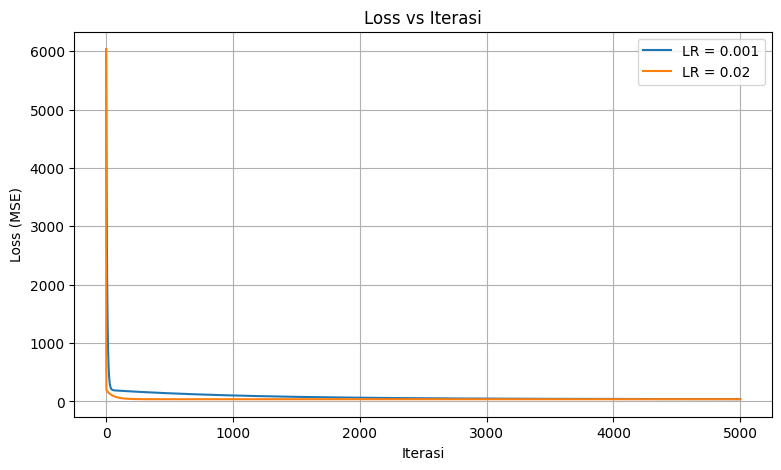

In [96]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history_ = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)

        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X.dot(self.coef_)
            error = y_pred - y
            d_intercept = (2/n_samples) * np.sum(error)
            d_coef = (2/n_samples) * X.T.dot(error)

            self.intercept_ -= self.learning_rate * d_intercept
            self.coef_ -= self.learning_rate * d_coef
            self.loss_history_.append(np.mean(error ** 2))
        return self

lr_list = [0.001, 0.02]
plt.figure(figsize=(9, 5))
for lr_val in lr_list:
    gd = LinearRegressionGD(learning_rate=lr_val, n_iterations=5000)
    gd.fit(X_train, y_train)
    plt.plot(gd.loss_history_, label=f'LR = {lr_val}')

plt.title('Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

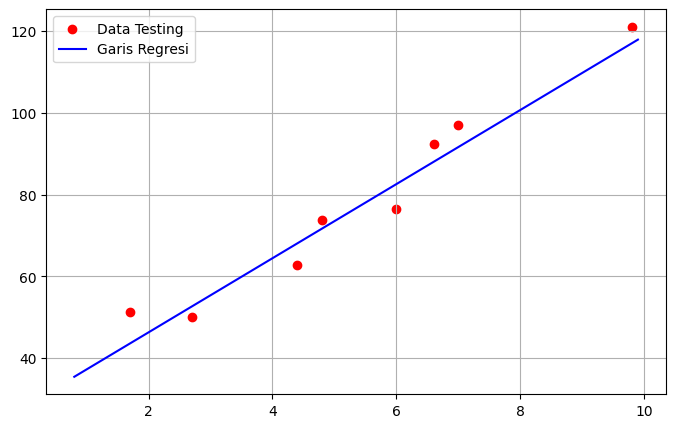

Biaya Iklan Rp 4.5 juta -> Prediksi Penjualan: Rp 69.00 juta
Biaya Iklan Rp 7.0 juta -> Prediksi Penjualan: Rp 91.67 juta
Biaya Iklan Rp 12.0 juta -> Prediksi Penjualan: Rp 136.99 juta


In [97]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='red', label='Data Testing')
X_line = np.linspace(X_ads.min(), X_ads.max(), 100)
plt.plot(X_line, b + m * X_line, color='blue', label='Garis Regresi')
plt.legend()
plt.grid(True)
plt.show()

biaya_baru = np.array([4.5, 7.0, 12.0])
prediksi = b + m * biaya_baru
for b_iklan, pred in zip(biaya_baru, prediksi):
    print(f"Biaya Iklan Rp {b_iklan} juta -> Prediksi Penjualan: Rp {pred:.2f} juta")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

In [98]:
# Jawaban B1
X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

X_e_train, X_e_test, y_e_train, y_e_test = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history_ = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)

        for _ in range(self.n_iterations):
            z = self.intercept_ + X.dot(self.coef_)
            y_pred = sigmoid(z)
            error = y_pred - y

            d_intercept = (1/n_samples) * np.sum(error)
            d_coef = (1/n_samples) * X.T.dot(error)

            self.intercept_ -= self.learning_rate * d_intercept
            self.coef_ -= self.learning_rate * d_coef

            eps = 1e-15
            y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history_.append(loss)
        return self

log_model = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_e_train, y_e_train)

print(f"Intercept (b) : {log_model.intercept_:.4f}")
print(f"Koefisien m1  : {log_model.coef_[0]:.4f}")
print(f"Koefisien m2  : {log_model.coef_[1]:.4f}")

Intercept (b) : -8.8744
Koefisien m1  : 0.7590
Koefisien m2  : 0.7943


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [99]:
# Jawaban B2
X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

X_e_train, X_e_test, y_e_train, y_e_test = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history_ = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)

        for _ in range(self.n_iterations):
            z = self.intercept_ + X.dot(self.coef_)
            y_pred = sigmoid(z)
            error = y_pred - y

            d_intercept = (1/n_samples) * np.sum(error)
            d_coef = (1/n_samples) * X.T.dot(error)

            self.intercept_ -= self.learning_rate * d_intercept
            self.coef_ -= self.learning_rate * d_coef

            eps = 1e-15
            y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history_.append(loss)
        return self

log_model = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_e_train, y_e_train)

print(f"Intercept (b) : {log_model.intercept_:.4f}")
print(f"Koefisien m1  : {log_model.coef_[0]:.4f}")
print(f"Koefisien m2  : {log_model.coef_[1]:.4f}")

Intercept (b) : -8.8744
Koefisien m1  : 0.7590
Koefisien m2  : 0.7943


**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [100]:
# Jawaban B3
def evaluate_classification(X, y, model, threshold=0.5):
    z = model.intercept_ + X.dot(model.coef_)
    probs = sigmoid(z)
    preds = (probs >= threshold).astype(int)

    tp = np.sum((preds == 1) & (y == 1))
    tn = np.sum((preds == 0) & (y == 0))
    fp = np.sum((preds == 1) & (y == 0))
    fn = np.sum((preds == 0) & (y == 1))

    acc = (tp + tn) / len(y)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    cm = np.array([[tn, fp], [fn, tp]])
    return acc, cm, precision, recall, f1

for th in [0.3, 0.5, 0.7]:
    acc, cm, prec, rec, f1 = evaluate_classification(X_e_test, y_e_test, log_model, threshold=th)
    print(f"Threshold {th} -> Acc: {acc:.2f}, Precision: {prec:.2f}, Recall: {rec:.2f}")

Threshold 0.3 -> Acc: 0.87, Precision: 0.75, Recall: 1.00
Threshold 0.5 -> Acc: 0.87, Precision: 0.75, Recall: 1.00
Threshold 0.7 -> Acc: 0.93, Precision: 1.00, Recall: 0.83


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

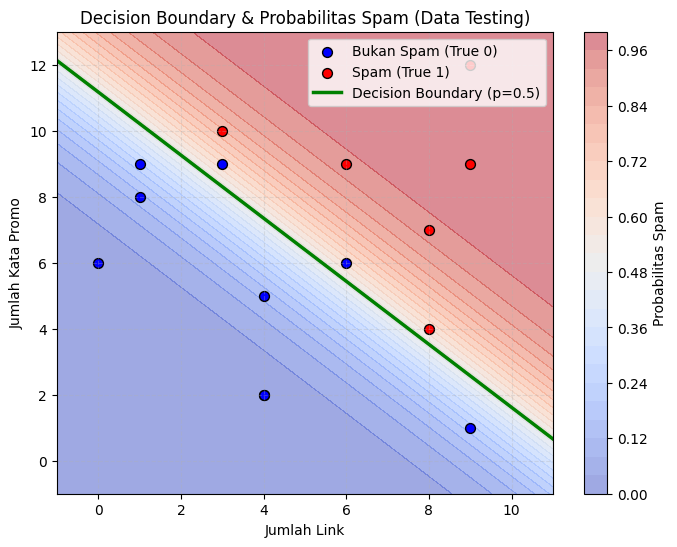

In [101]:
# Jawaban B4 – Visualisasi Decision Boundary
plt.figure(figsize=(8, 6))

x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs_grid = sigmoid(log_model.intercept_ + grid_points.dot(log_model.coef_)).reshape(xx.shape)

plt.contourf(xx, yy, probs_grid, levels=25, cmap='coolwarm', alpha=0.5)
plt.colorbar(label='Probabilitas Spam')

plt.scatter(X_e_test[y_e_test==0, 0], X_e_test[y_e_test==0, 1], color='blue', label='Bukan Spam (True 0)', edgecolor='k', s=50)
plt.scatter(X_e_test[y_e_test==1, 0], X_e_test[y_e_test==1, 1], color='red', label='Spam (True 1)', edgecolor='k', s=50)

x1_line = np.linspace(x_min, x_max, 100)
x2_line = -(log_model.intercept_ + log_model.coef_[0] * x1_line) / log_model.coef_[1]
plt.plot(x1_line, x2_line, color='green', linewidth=2.5, label='Decision Boundary (p=0.5)')

plt.title('Decision Boundary & Probabilitas Spam (Data Testing)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [102]:
def evaluate_classification(X, y, model, threshold=0.5):
    z = model.intercept_ + X.dot(model.coef_)
    probs = sigmoid(z)
    preds = (probs >= threshold).astype(int)

    tp = np.sum((preds == 1) & (y == 1))
    tn = np.sum((preds == 0) & (y == 0))
    fp = np.sum((preds == 1) & (y == 0))
    fn = np.sum((preds == 0) & (y == 1))

    acc = (tp + tn) / len(y)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    cm = np.array([[tn, fp], [fn, tp]])
    return acc, cm, precision, recall, f1

for th in [0.3, 0.5, 0.7]:
    acc, cm, prec, rec, f1 = evaluate_classification(X_e_test, y_e_test, log_model, threshold=th)
    print(f"Threshold {th} -> Acc: {acc:.2f}, Precision: {prec:.2f}, Recall: {rec:.2f}")

Threshold 0.3 -> Acc: 0.87, Precision: 0.75, Recall: 1.00
Threshold 0.5 -> Acc: 0.87, Precision: 0.75, Recall: 1.00
Threshold 0.7 -> Acc: 0.93, Precision: 1.00, Recall: 0.83


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [103]:
# Jawaban B6
new_emails = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

z_new = log_model.intercept_ + new_emails.dot(log_model.coef_)
probs_new = sigmoid(z_new)
preds_new = (probs_new >= 0.5).astype(int)

for i, (link, promo) in enumerate(new_emails):
    status = "Spam" if preds_new[i] == 1 else "Bukan Spam"
    print(f"E{i+1} -> Prob: {probs_new[i]:.4f} | Status: {status}")

E1 -> Prob: 0.0015 | Status: Bukan Spam
E2 -> Prob: 0.4223 | Status: Bukan Spam
E3 -> Prob: 0.9973 | Status: Spam
E4 -> Prob: 0.7991 | Status: Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression menggunakan fungsi sigmoid untuk memetakan output ke rentang [0, 1] sebagai probabilitas klasifikasi biner. Dinamai "regression" karena berbasis model regresi linier sebelum fungsi sigmoid diterapkan.

**Jawaban C2:** Normal Equation menghitung parameter secara langsung via invers matriks (bagus untuk data kecil), sedangkan Gradient Descent memperbarui parameter secara iteratif (efisien untuk data berskala besar).

**Jawaban C3:** Evaluasi dilakukan pada data testing untuk mengukur kemampuan generalisasi model terhadap data baru. Overfitting terjadi ketika model terlalu menghafal data training sehingga gagal di data testing.

**Jawaban C4:** Linear Regression memakai MSE karena asumsi galat kontinu, sementara Logistic Regression memakai log loss agar fungsi cost bernilai cembung (convex) terhadap probabilitas prediksi.

**Jawaban C5:** Perbedaan hasil angka disebabkan oleh perbedaan nilai random_state pada pembagian train-test split dan inisialisasi bobot acak.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [104]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

sk_lr = SkLinearRegression()
sk_lr.fit(X_train, y_train)
print("Sklearn LR Intercept:", sk_lr.intercept_, "Coef:", sk_lr.coef_)

sk_log = SkLogisticRegression(penalty='l2', C=1.0, solver='lbfgs')
sk_log.fit(X_e_train, y_e_train)
print("Sklearn LogReg Intercept:", sk_log.intercept_, "Coef:", sk_log.coef_)

Sklearn LR Intercept: 28.21064299195288 Coef: [9.06507176]
Sklearn LogReg Intercept: [-8.20014502] Coef: [[0.69349902 0.73678244]]


**Jawaban Bonus (analisis):** Koefisien Linear Regression identik karena menggunakan metode matematis yang sama. Pada Logistic Regression, koefisien sedikit berbeda karena Scikit-Learn menerapkan regularisasi L2 secara default, sedangkan implementasi manual menggunakan pure gradient descent tanpa regularisasi.